In [7]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import lineStyles

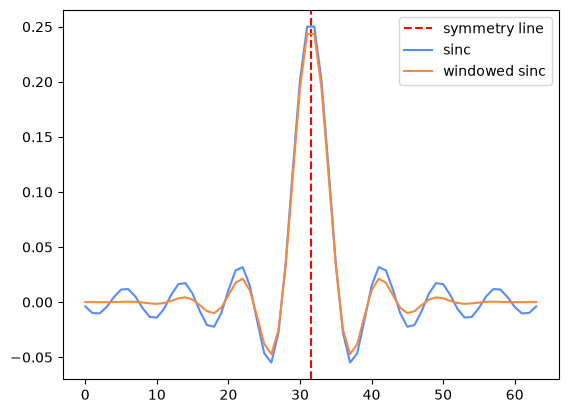

In [9]:
fs = 8000
cutoff = 1000
num_taps = 64

window = np.blackman(num_taps)

n = np.arange(num_taps) - (num_taps - 1) / 2
h = np.sinc(2 * n * cutoff / fs)
h_windowed = h * window

h /= np.sum(h)
h_windowed /= np.sum(h_windowed)

plt.axvline((num_taps - 1) / 2, color='red', linestyle='dashed', label='symmetry line')
plt.plot(h, label="sinc")
plt.plot(h_windowed, label="windowed sinc")
plt.legend()

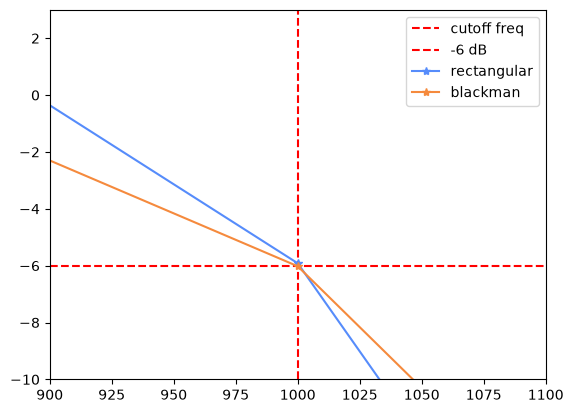

In [10]:
H = np.fft.fft(h)[:num_taps//2]
H_windowed = np.fft.fft(h_windowed)[:num_taps//2]
f = np.fft.fftfreq(num_taps, 1 / fs)[:num_taps//2]

plt.axvline(cutoff, color='red', linestyle='dashed', label='cutoff freq')
plt.axhline(-6, color='red', linestyle='dashed', label='-6 dB')


plt.plot(f, 20 * np.log10(np.abs(H)), '*-', label="rectangular")
plt.plot(f, 20 * np.log10(np.abs(H_windowed)), '*-', label="blackman")

plt.ylim(-10, 3)
plt.xlim(cutoff - 100, cutoff + 100)
plt.legend()

### Сравнение fir_lowpass и scipy.signal.firwin

In [11]:
import scipy.signal as sg
from dsp_lab.filters import fir_lowpass

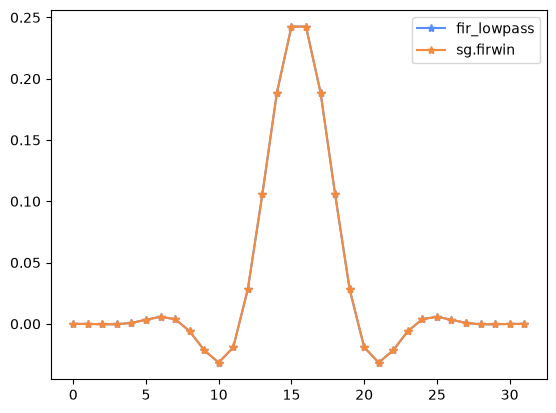

In [12]:
numtaps, cutoff, fs, window = 32, 1000, 8000, "blackman"

h = fir_lowpass(numtaps, cutoff, fs, window)
h_expected = sg.firwin(numtaps, cutoff, window=window, fs=fs)

plt.plot(h, "*-", label="fir_lowpass")
plt.plot(h_expected, "*-", label="sg.firwin")
plt.legend()